# Normalization & Scaling: Visium HD (16-µm Binned)

## Introduction

Following quality control and spatial artifact filtering in [notebook 05](05-quality_control_VisiumHD_binned.ipynb), we now transform *raw transcript counts* into *statistically comparable expression profiles* across our 16-µm square grid.

In [notebook 07](07-normalization_VisiumHD_segmented.ipynb), we established the observation-level normalization and feature-scaling framework for segmented single cells. When transitioning from segmented cell polygons (`SpatialFeatureExperiment`) to regular square capture bins (`SpatialExperiment`), two fundamental container and biological distinctions emerge:

1. **Biological meaning of size factors (cellularity vs. cell volume):** In segmented data, each capture unit approximates a biological cell, and size factors reflect cell volume, metabolic RNA content, and capture efficiency. In contrast, a 16-µm bin spans a rigid geometric square (256 µm²) that does not conform to cell membranes. Bins sample variable mixtures of 1–3 dense epithelial/cancer cell nuclei, cytoplasmic fragments, or acellular extracellular matrix. Consequently, bin size factors ($s_i$) primarily capture **local cellularity (cellular packing density)** alongside technical sequencing depth. Depth-normalized log-counts in binned data reflect expression *relative to total sampled RNA density* (an RNA concentration proxy) rather than single-cell expression.
2. **Container & memory architecture (`DelayedMatrix` vs. in-memory sparse matrices):** Segmented cell assays are held in active RAM as sparse matrices (`dgCMatrix`). Our 16-µm binned dataset contains 18,027 active genes across 21,278 bins backed by an on-disk HDF5 file (`DelayedMatrix`). Applying standard operations in memory would instantiate dense double-precision floating-point arrays (~3 GB), risking memory exhaustion. We leverage `scuttle::logNormCounts()` with Bioconductor delayed-array block processing to compute library size factors and register the variance-stabilized `logcounts` assay *lazily* without realizing the entire matrix into active memory.

> For the theoretical derivation of size-factor mechanics, variance stabilization, and alternative frameworks (such as deconvolution pooling via `scuttle::computePooledFactors()`, negative binomial regularized models via `SCTransform()`, and spatially-aware normalization methods), please consult the original SIB lecture slides and [the companion study guide](../assets/notes/05-normalization.md).

## Learning objectives

- **Implement out-of-memory library-size normalization:** Apply `scuttle::logNormCounts()` to an HDF5-backed `SpatialExperiment` container, populating the variance-stabilized `logcounts` assay via delayed arithmetic operations.
- **Diagnose spatial patterns in bin-level cellularity:** Inspect the empirical size factor distribution ($s_i$) and project values across full-resolution tissue coordinates using `ggspavis::plotCoords()` to map high-cellularity tumor nests against transcript-sparse desmoplastic stroma.
- **Evaluate raw count confounding on canonical CRC markers:** Compare raw UMI counts against normalized `logcounts` for canonical colorectal adenocarcinoma markers (e.g., `CEACAM5`), demonstrating the removal of technical depth bias.
- **Perform targeted feature-level scaling:** Realize a focused panel of highly variable colorectal markers (`PIGR`, `CEACAM5`, `MUC17`, `OLFM4`) and apply row-wise Z-score standardization (*mean = 0, variance = 1*) following the Normalization vs. Scaling Golden Rule.
- **Evaluate spatially-aware normalization on geometric grids:** Simulate k-NN spatial smoothing (k = 36, spanning a ≈ 100 µm diameter neighborhood) to quantify boundary distortion ratios ($s_i / \overline{s_i}$) across adenocarcinoma–stroma interfaces, demonstrating why global depth normalization remains preferable over spatial smoothing on heterogeneous tissue.
- **Serialize normalized HDF5 objects:** Export the final `SpatialExperiment` object containing both `counts` and `logcounts` assays back to disk using `HDF5Array::saveHDF5SummarizedExperiment()`.

## Environment setup

We initialize the R environment by attaching the Bioconductor libraries required for out-of-memory `SpatialExperiment` manipulation, delayed-array statistics, library-size normalization, and spatial coordinate visualization.

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial container & out-of-memory HDF5 backend
  library(SpatialExperiment)
  library(HDF5Array)
  library(DelayedArray)
  library(DelayedMatrixStats)

  # Normalization & single-cell statistics
  library(scuttle)

  # Spatial visualization & plotting aesthetics
  library(ggspavis)
  library(ggplot2)
  library(patchwork)

  # Spatial neighborhood graphs for smoothing evaluation
  library(BiocNeighbors)
}))

# Enforce reproducible random number generation
set.seed(42)

### Restoring the QC-filtered 16-µm binned dataset

We restore our quality-controlled 16-µm binned `SpatialExperiment` object. If the filtered object was serialized at the conclusion of [notebook 05](05-quality_control_VisiumHD_binned.ipynb) into `output/spe_visiumhd_binned_qc`, we load it directly via `HDF5Array::loadHDF5SummarizedExperiment()`.

In [2]:
qc_dir <- "output/spe_visiumhd_binned_qc"

# Load pre-saved QC-filtered binned object
spe <- loadHDF5SummarizedExperiment(dir = qc_dir)

# Verify object architecture, assays, and final matrix dimensions
spe

class: SpatialExperiment 
dim: 18027 21278 
metadata(2): resouces spatialList
assays(1): counts
rownames(18027): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(4): ID Symbol Type subsets_Mito
colnames(21278): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(32): barcode in_tissue ... global_outliers discard
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

Following our two-tiered quality control, the restored container retains exactly **21,278 high-quality bins** (purging 688 low-quality or edge-dropout bins) and **18,027 active genes** (pruning 58 unexpressed features).

## Size-factor log-normalization on `DelayedMatrix`

### Mathematical framework & out-of-memory execution

For each gene $j$ in 16-µm bin $i$, the depth-normalized log-expression value $Y_{ij}$ is defined as:

$$
Y_{ij} = \log_e \left( \frac{X_{ij}}{s_i} + 1 \right)
$$

where $X_{ij}$ is the raw UMI count, $s_i$ is the bin-specific size factor scaled to unit mean ($\text{mean}(s_i) = 1.0$), and $+1$ is the variance-stabilizing pseudocount.

Because `counts(spe)` is an HDF5-backed `DelayedMatrix`, `scuttle::logNormCounts()` executes column-sum aggregations in chunked blocks, calculates $s_i$, and populates the `logcounts` assay as a `DelayedMatrix` without allocating dense matrices in memory.

In [3]:
# Verify existing assay slots prior to normalization
assayNames(spe)

[1] "counts"

In [4]:
# Confirm assay is out-of-memory DelayedMatrix
is(counts(spe), "DelayedMatrix")

[1] TRUE

In [5]:
# Compute size factors and populate the logcounts assay via delayed block processing
spe <- logNormCounts(spe)

# Verify that logcounts is successfully registered alongside raw counts
assayNames(spe)

Warning message in .library_size_factors(assay(x, assay.type), ...):
"'librarySizeFactors' est obsolète.
Utilisez plutôt ‘scrapper::centerSizeFactors’.
Voir help("Deprecated")"
Warning message in .local(x, ...):
"'normalizeCounts' est obsolète.
Utilisez plutôt ‘scrapper::normalizeCounts’.
Voir help("Deprecated")"


[1] "counts"    "logcounts"

In [6]:
# Confirm that new assays retain an out-of-memory DelayedMatrix backend
is(logcounts(spe), "DelayedMatrix")

[1] TRUE

### Quantitative evaluation of size factor distribution

In [notebook 07](07-normalization_VisiumHD_segmented.ipynb), our segmented `SpatialFeatureExperiment` container included computed size factors inside a hidden internal metadata slot (`int_colData(sfe)$sizeFactor`), requiring us to manually extract and promote them into visible `colData` before `Voyager` could plot them. 

Here, in our binned `SpatialExperiment` container, `scuttle::logNormCounts()` automatically registers the calculated depth multipliers directly into visible `colData(spe)` under the canonical name **`sizeFactor`**. The official extractor `sizeFactors(spe)` acts as a direct accessor to this column. Therefore, we do not need to manually promote or duplicate any columns.

In [7]:
# Inspect available cell-level metadata attributes registered in colData
names(colData(spe))

[1] "barcode"                       "in_tissue"                    
 [3] "array_row"                     "array_col"                    
 [5] "bin_size"                      "square_002um"                 
 [7] "square_008um"                  "square_016um"                 
 [9] "cell_id"                       "in_nucleus"                   
[11] "in_cell"                       "sample_id"                    
[13] "sum"                           "detected"                     
[15] "subsets_Mito_sum"              "subsets_Mito_detected"        
[17] "subsets_Mito_percent"          "total"                        
[19] "qc_lib_size"                   "qc_detected"                  
[21] "qc_mito_prop"                  "sum_log"                      
[23] "sum_outliers"                  "sum_z"                        
[25] "detected_log"                  "detected_outliers"            
[27] "detected_z"                    "subsets_Mito_percent_outliers"
[29] "subsets_Mito_percent_z"        "local_outliers"               
[31] "global_outliers"               "discard"                      
[33] "sizeFactor"

In [8]:
# Query size factors directly via the official accessor
sf_values <- sizeFactors(spe)

# Five-number summary of 16-µm bin size factors
summary(sf_values)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.07519 0.50914 0.86618 1.00000 1.40747 3.93539 

In our segmented cell dataset, cell-level size factors exhibited a median of `0.7598` and an upper extreme reaching `8.9815` (nearly 9-times unity), driven by individual hypertrophic, hyper-transcribing cribriform adenocarcinoma tumor cells. In our 16-µm binned dataset, the empirical distribution reveals the direct impact of geometric binning:

1. **Upper bound compression (max `8.9815` → `3.9354`):** Because each 16-µm square pools transcripts across a uniform area of 256 µm², spatial averaging dampens extreme single-cell transcriptional bursts and segmentation artifacts, capping maximum library size at ≈ 3.94-times the array mean.
2. **Median shift (median `0.7598` → `0.8662`):** While small, transcript-sparse stromal fibroblasts pulled the single-cell median down to `0.76`, fixed 256 µm² bins frequently encompass 1–3 cells or overlapping cell fragments, shifting the median closer to unity (`0.87`).
3. **Histological cellularity gradient:** The interquartile range (`0.5091`–`1.4075`) spans a ≈ 2.8-fold dynamic range that directly delineates tissue density, from hypocellular fibrous stroma and vascular lumina ($s_i \le 0.51$) to densely packed neoplastic epithelial crypts ($s_i \ge 1.41$).

In [9]:
# Package the size factor vector into a rectangular data frame for ggplot2 aesthetic mapping
df_sf <- data.frame(size_factor = sf_values)

# Precalculate the empirical distribution median for histogram annotation lines
sf_median <- median(sf_values)

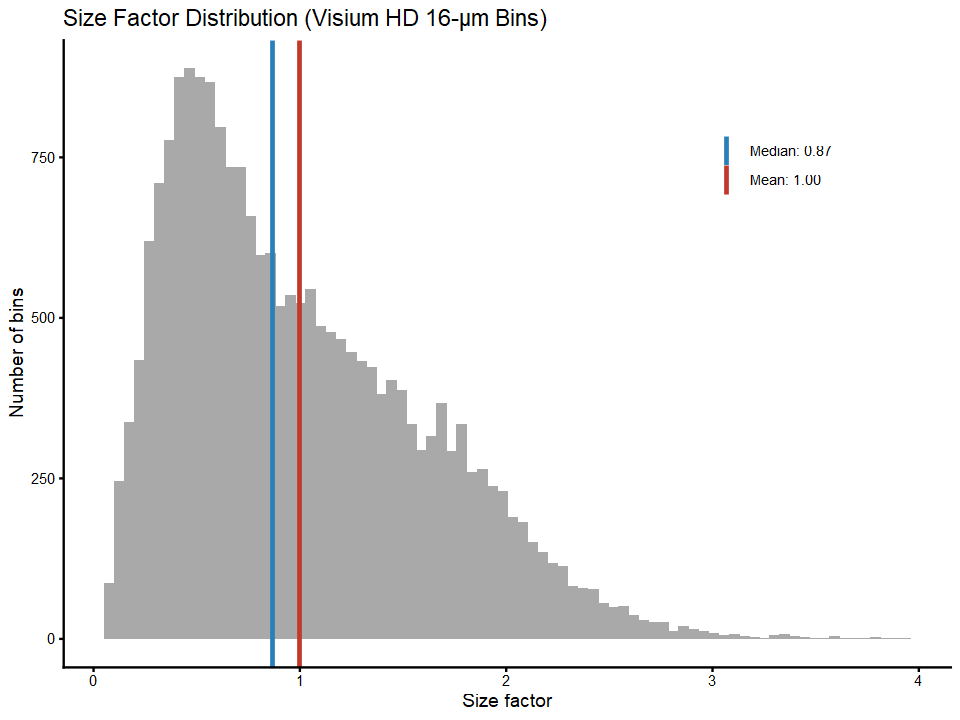

In [10]:
# Set canvas dimensions a little wider
options(repr.plot.width = 8, repr.plot.height = 6)

# Streamlined publication-style histogram
ggplot(df_sf, aes(x = size_factor)) +
  geom_histogram(bins = 80, fill = "darkgrey") +
  geom_vline(aes(xintercept = sf_median, color = "Median"), linewidth = 1) +
  geom_vline(aes(xintercept = mean(sf_values), color = "Mean"), linewidth = 1) +
  scale_color_manual(
    name = NULL, 
    breaks = c("Median", "Mean"), 
    values = c("Median" = "#2980B9", "Mean" = "#C0392B"), 
    labels = c("Median" = paste0("Median: ", round(sf_median, 2)), "Mean" = "Mean: 1.00")
  ) +
  labs(
    title = "Size Factor Distribution (Visium HD 16-µm Bins)", 
    x = "Size factor", 
    y = "Number of bins"
  ) +
  theme_classic() +
  theme(legend.position = c(0.8, 0.8))

While segmented cells displayed a single smooth continuum of cell volumes, as observed in [notebook 07](07-normalization_VisiumHD_segmented.ipynb), our 16-µm binned histogram exhibits a prominent primary mode at $s_i \approx 0.5$ followed by a **distinct secondary plateau / shoulder centered between 0.85 and 1.2** (straddling the median of 0.87 and unit mean of 1.00). Deconvolving futher the tissue compartments, we can notice:

* **The low-depth mode ($s_i \approx 0.3$–$0.7$):** Maps to hypocellular desmoplastic stroma, smooth muscle fibers, and vascular lumina, where a 256 µm² area predominantly encompasses cell-sparse collagenous matrix with minimal transcript density.
* **The central shoulder ($s_i \approx 0.85$–$1.2$):** Formed by organized mucosal crypt monolayers and boundary-straddling interface bins (where partial volume averaging blends epithelial cells with adjacent stroma).
* **The heavy neoplastic tail ($s_i \ge 1.4$):** Delineates crowded cribriform adenocarcinoma glands where elevated nuclear-to-cytoplasmic ratios pack 2–3 overlapping malignant nuclei into a single 16-µm bin, generating 2- to 4-fold greater library depth than the slide-wide average.

### Spatial diagnostic mapping of size factors

We now map size factors across physical coordinates using `ggspavis::plotCoords()`.

In `SpatialExperiment`, `spatialCoords(spe)` stores full-resolution slide pixel coordinates (`pxl_col_in_fullres`, `pxl_row_in_fullres`). Because microscope imaging rasters define pixel row 0 at the top, standard Cartesian coordinate rendering results in a vertical Y-axis inversion relative to the biological orientation observed in `Voyager` micron plots.

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


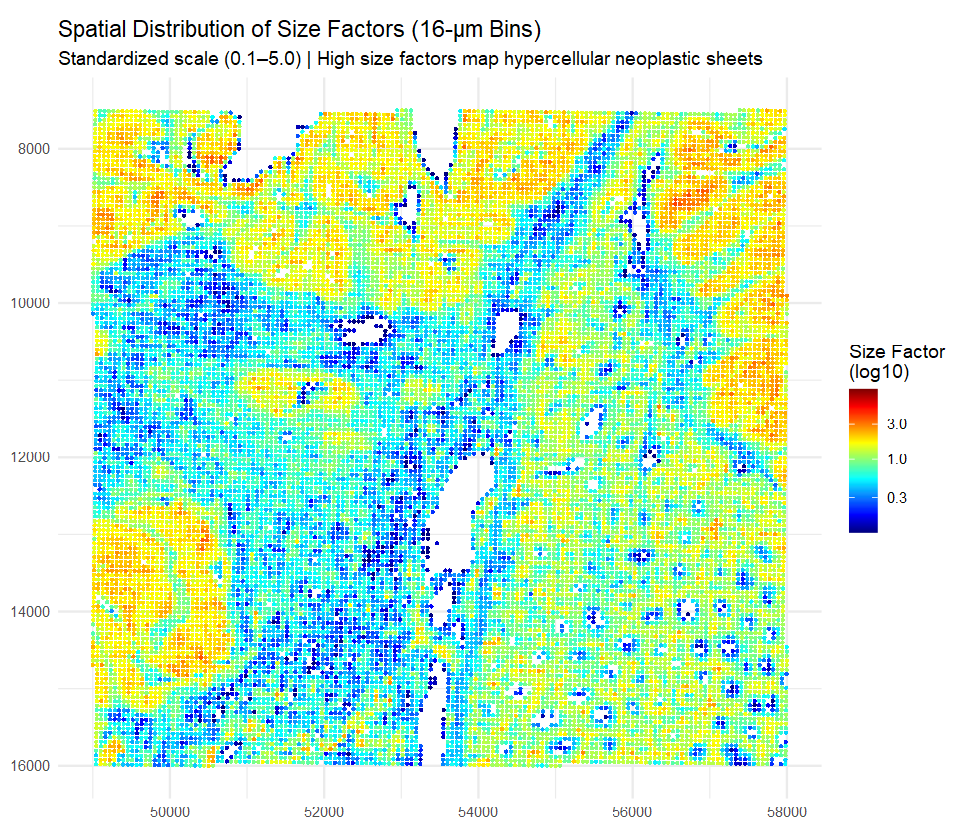

In [11]:
# Set canvas dimensions
options(repr.plot.width = 8, repr.plot.height = 7)

plotCoords(spe, annotate = "sizeFactor", point_size = 0.6) +
  scale_color_gradientn(
    colors = pals::jet(),
    trans = "log10",
    limits = c(0.1, 9),
    breaks = c(0.3, 1.0, 3.0),
    labels = c("0.3", "1.0", "3.0"),
    oob = scales::squish,
    name = "Size Factor\n(log10)"
  ) +
  labs(
    title = "Spatial Distribution of Size Factors (16-µm Bins)",
    subtitle = "Standardized scale (0.1–5.0) | High size factors map hypercellular neoplastic sheets"
  ) +
  theme_minimal() + 
  theme(
    axis.title = element_blank(), 
    # plot.title = element_text(face = "bold", size = 13), 
    # plot.subtitle = element_text(color = "gray30", size = 10), 
    # legend.position = "right"
  )

Comparing our standardized binned map against the segmented cells reveals the immediate tradeoff of geometric binning. While microscope pixel coordinates naturally invert the vertical axis relative to physical micron space, the primary biological consequence is a substantial loss of spatial granularity. Within the adenocarcinoma mass, pooling RNA across rigid 256 µm² squares homogenizes local variation into monolithic yellow-to-orange cellularity blocks ($s_i \ge 1.5$), smoothing out the individual hypertrophic cells, apoptotic microniches, and glandular clefts resolved by StarDist segmentation we observed in [notebook 07](07-normalization_VisiumHD_segmented.ipynb). Furthermore, subtle intra-tumoral gradients and delicate transitions at the stroma-infiltrating boundary are largely obscured, compressing fine single-cell heterogeneity into broader, macro-level cellularity domains.

### Visualizing the normalization effect: raw counts vs. logcounts

To evaluate how library-size normalization corrects technical depth variation, we visualize the canonical colorectal adenocarcinoma marker **`CEACAM5`** (carcinoembryonic antigen-related cell adhesion molecule 5).

In raw UMI counts, `CEACAM5` intensity is conflated with total library depth, creating artificial expression spikes in dense multicell bins. In `logcounts`, depth confounding is eliminated, revealing genuine biological over-expression strictly localized to malignant epithelial margins and cribriform glandular lumina.

In [12]:
# Extract raw counts and log-normalized counts for CEACAM5
spe[["CEACAM5_raw"]] <- as.numeric(counts(spe)["CEACAM5", ])
spe[["CEACAM5_lognorm"]] <- as.numeric(logcounts(spe)["CEACAM5", ])

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


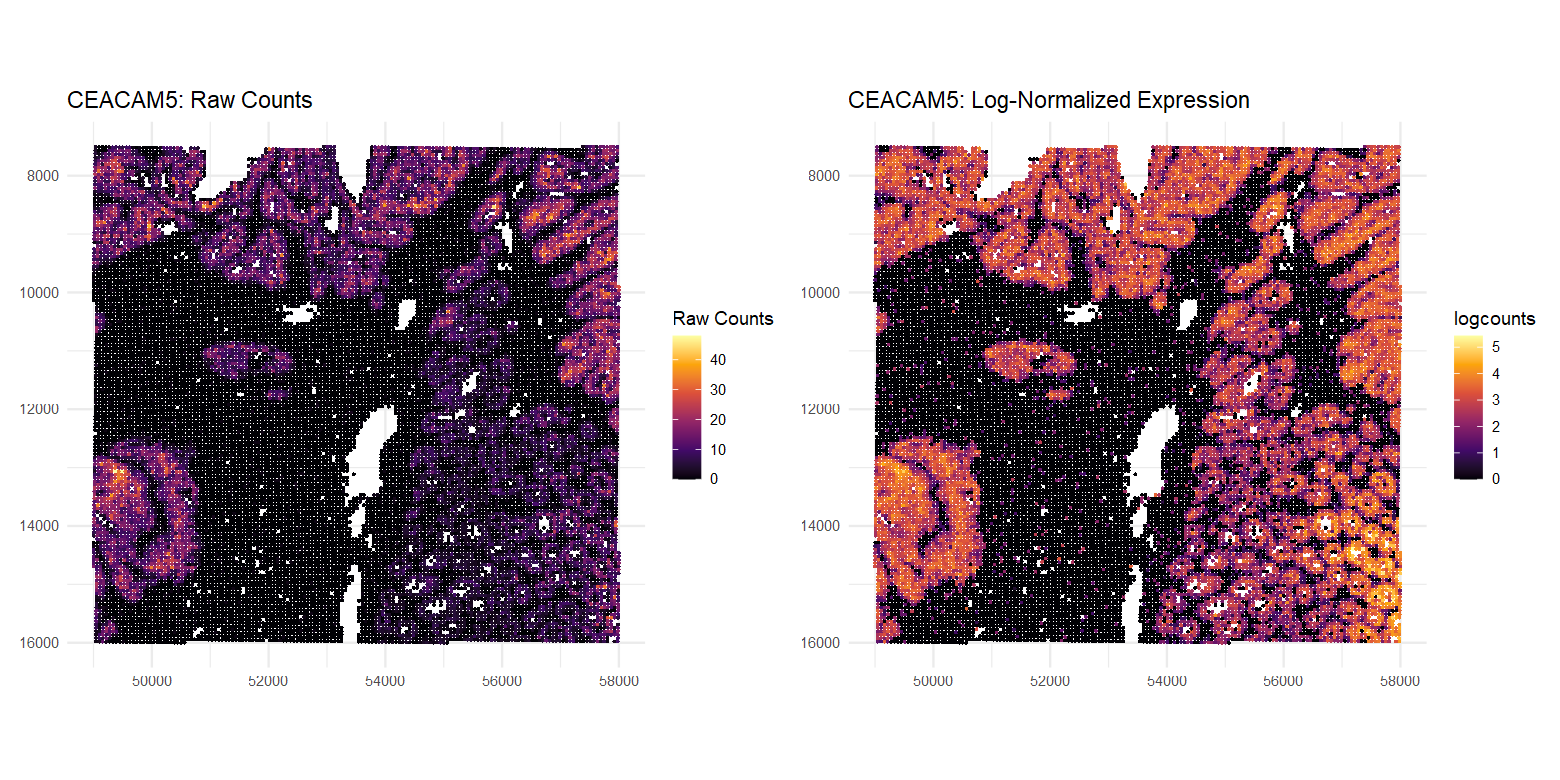

In [13]:
# Set figure canvas dimensions for side-by-side viewing
options(repr.plot.width = 13, repr.plot.height = 6.5)

# Raw counts (confounded by bin cellularity & capture depth)
p_raw <- plotCoords(spe, annotate = "CEACAM5_raw", point_size = 0.5) +
  scale_color_viridis_c(
    option = "inferno",
    name = "Raw Counts"
  ) +
  labs(
    title = "CEACAM5: Raw Counts"
  ) +
  theme_minimal() +
  theme(
    axis.title = element_blank(),
  )

# Log-normalized counts (depth-adjusted expression)
p_norm <- plotCoords(spe, annotate = "CEACAM5_lognorm", point_size = 0.5) +
  scale_color_viridis_c(
    option = "inferno",
    name = "logcounts"
  ) +
  labs(
    title = "CEACAM5: Log-Normalized Expression"
  ) +
  theme_minimal() +
  theme(
    axis.title = element_blank(),
  )

# Render side-by-side
p_raw + p_norm

In raw counts, `CEACAM5` expression appears patchy and disjointed across the adenocarcinoma sheets (left and upper margins) and crypts (bottom-right). Only a subset of hypercellular bins with high UMI sampling depth reach peak intensity (yellow points ≥ 30 counts), while morphologically identical neighboring tumor bins remain dim or dark, conflating technical capture efficiency with authentic gene activity.

Following library-size log-normalization (`logcounts`), dividing by bin size factors ($s_i$) and log-transforming with a pseudocount successfully decouples biological transcription from local sampling depth. The entire cribriform adenocarcinoma territory and crypt epithelium coalesce into glowing, cohesive fields of elevated expression (≈ 3–5 logcounts), sharply demarcated against the pitch-black desmoplastic stroma and submucosal vasculature. Just as log-normalization unmasked mucosal crypt integrity for `PIGR` in single cells, it establishes cohesive neoplastic tissue borders for `CEACAM5` in binned space, confirming that size-factor scaling operates robustly across distinct histological lineages and spatial representations.

### On spatially-aware normalization in binned space

Having confirmed that standard depth normalization decouples biological expression from local sampling variation, we consider whether spatially-aware normalization frameworks (such as `SpaNorm`) offer any advantage here. 

In [notebook 07](07-normalization_VisiumHD_segmented.ipynb), we evaluated spatially-aware size-factor smoothing, demonstrating that averaging library sizes across spatial neighbors introduces severe distortion ratios (up to 5.7-fold) along sharp adenocarcinoma–stroma boundaries. Because fixed 16-µm bins already perform intrinsic spatial pooling over 256 µm² areas, applying an additional layer of spatial smoothing on binned data would over-smooth genuine biological interfaces and exacerbate partial-volume blurring. Standard observation-level normalization via `scuttle::logNormCounts()` remains the optimal, distortion-free foundation.

## Feature-level scaling

### Scaling on out-of-memory binned data

Having established the Golden Rule in [notebook 07](07-normalization_VisiumHD_segmented.ipynb)—that observation-level depth normalization must strictly precede gene-level Z-score standardization, and that scaling must never overwrite `logcounts` due to loss of sparsity—we apply feature scaling with two key adaptations for binned data:

1. **DelayedMatrix memory preservation:** While segmented single-cell matrices are held in RAM, our binned dataset is backed by an out-of-memory HDF5 `DelayedMatrix`. Attempting full-matrix row-wise scaling across all 18,027 genes would force the realization of a dense ≈ 3 GB floating-point matrix in memory. Instead, feature scaling is performed selectively: realized in memory only for focused marker panels or restricted downstream to top Highly Variable Genes (HVGs) prior to PCA.
2. **Dampened variance from grid averaging:** Because each 16-µm bin pools transcripts across 1–3 cells, extreme single-cell transcriptional bursts are diluted, producing more stable gene variances across bins than in segmented cells.

We realize a canonical panel of colorectal cancer markers, i.e., `PIGR` (mucosal epithelium), `CEACAM5` (adenocarcinoma), `MUC17` (goblet cells), and `OLFM4` (stem/crypt base), and standardize their normalized profiles to zero mean and unit variance.

In [14]:
# Define canonical CRC and epithelial marker panel
crc_markers <- c("PIGR", "CEACAM5", "MUC17", "OLFM4")
stopifnot(all(crc_markers %in% rownames(spe)))

In [15]:
# Realize log-normalized values into RAM for the target marker panel
logcounts_subset <- as.matrix(logcounts(spe)[crc_markers, ])

# Compute row-wise Z-score transformation
# base::scale operates column-wise; transposing twice applies standardization across bins
scaled_markers <- t(scale(t(logcounts_subset)))

# Verify empirical mean = 0 and standard deviation = 1 across 21,278 bins
data.frame(
  Gene = crc_markers,
  Mean = round(rowMeans(scaled_markers), 4),
  SD   = round(apply(scaled_markers, 1, sd), 4)
)

,Gene,Mean,SD
,<chr>,<dbl>,<dbl>
PIGR,PIGR,0,1
CEACAM5,CEACAM5,0,1
MUC17,MUC17,0,1
OLFM4,OLFM4,0,1


In [16]:
# Preview the scaled matrix across the first five bins
print(round(scaled_markers[, 1:5], 3))

        s_016um_00144_00175-1 s_016um_00204_00145-1 s_016um_00237_00273-1
PIGR                   -0.539                -0.539                -0.539
CEACAM5                 0.510                -0.106                 0.866
MUC17                  -0.232                -0.232                -0.232
OLFM4                  -0.439                -0.439                -0.439
        s_016um_00191_00159-1 s_016um_00245_00233-1
PIGR                   -0.539                -0.539
CEACAM5                -0.948                 0.956
MUC17                  -0.232                -0.232
OLFM4                  -0.439                -0.439


For genes with zero detected transcripts in these previewed bins (`PIGR`, `MUC17`, and `OLFM4`), normalized zeros ($Y_{ij} = 0$) map to identical negative constants ($-\mu_j / \sigma_j$, such as `-0.539` for `PIGR` and `-0.232` for `MUC17`). This demonstrates why scaling destroys matrix sparsity and must never replace `logcounts` in primary storage.

In contrast to the unexpressed mucosal and crypt markers, `CEACAM5` exhibits dynamic positive Z-scores (up to `+0.956` in bin `...00245`), confirming active adenocarcinoma marker expression well above the slide-wide mean.

## Finalization

### Saving the normalized SpatialExperiment object

Because our `SpatialExperiment` container utilizes an out-of-memory `DelayedMatrix` backend for both `counts` and `logcounts`, we serialize the complete dataset to disk using `HDF5Array::saveHDF5SummarizedExperiment()`.

In [17]:
# Define output directory path for the normalized binned object
norm_out_dir <- "output/spe_visiumhd_binned_normalized"

# Remove existing directory if present to guarantee clean serialization
if (dir.exists(norm_out_dir)) {
  unlink(norm_out_dir, recursive = TRUE)
}

# Serialize normalized SpatialExperiment object to disk (assays stored in HDF5)
saveHDF5SummarizedExperiment(
  x = spe, 
  dir = norm_out_dir, 
  replace = TRUE
)

In [18]:
# Confirm successful directory creation and exported HDF5 payload
list.files(norm_out_dir, full.names = TRUE)

[1] "output/spe_visiumhd_binned_normalized/assays.h5"
[2] "output/spe_visiumhd_binned_normalized/se.rds"

### Clearing the workspace

We clear the workspace and trigger garbage collection to release cached coordinate tables, visualization layers, and open HDF5 file handles before opening the next notebook.

In [19]:
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,9047487,483.2,15955135,852.1,15955135,852.1
Vcells,18517963,141.3,44550496,339.9,44550496,339.9
